# Only for tanh Activation Function

# Case 01: Normal

> Formula:
*  sqrt ( 1 / fan_in )
> fan_in = no of input comiing to the node

# Case 02: uniform
*  Forrmula:
> [-limit to limit]

> limit = sqrt(6/(fan_in+fan_out))

> fan_in = no of input coming to the node

> fan_out = no of input leaving to the node

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DL/dataset/ushape.csv', header=None, names=['X', 'Y', 'class'])

In [ ]:
df.sample(5)

,X,Y,class
72,-0.882308,0.072490,0.0
66,-0.148144,0.961587,0.0
41,0.641740,-0.393695,1.0
18,-0.237125,0.778760,0.0
50,1.404512,-0.007057,1.0


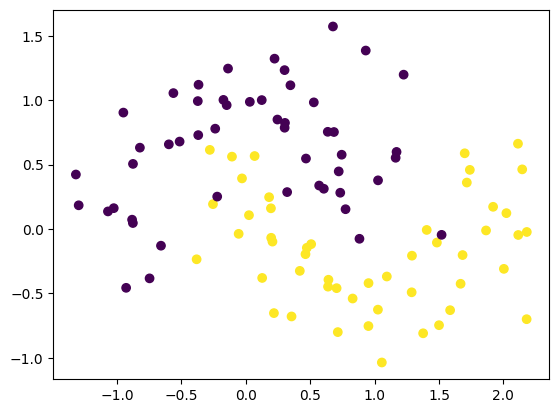

In [ ]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [ ]:
X= df[['X','Y']].values
y=df['class'].values

In [ ]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

# Xavier only applicable for tanh

In [ ]:
model = Sequential()

model.add(Dense(10,activation='tanh',input_dim=2))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(10,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.get_weights()

[array([[-0.5261985 , -0.433642  , -0.54144776,  0.20918864, -0.5478203 ,
          0.10926062, -0.07861233, -0.43074062, -0.5588731 , -0.16852349],
        [-0.06790817, -0.0399648 , -0.36085626,  0.4657994 ,  0.5589737 ,
         -0.5637006 , -0.70441073, -0.12178737, -0.00615633,  0.61902446]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.1453628 , -0.49143517,  0.08196998, -0.22162262,  0.2532614 ,
         -0.32282823, -0.16981146,  0.12962967,  0.09669697, -0.51711047],
        [-0.3584809 ,  0.39575768, -0.41619667, -0.41484588,  0.3702467 ,
          0.05579889, -0.21452272, -0.20814496,  0.38899654,  0.05308735],
        [-0.4935089 , -0.4894479 ,  0.49663973, -0.07085636, -0.30240935,
         -0.35392642,  0.5386983 ,  0.09320456, -0.23023796,  0.546471  ],
        [-0.1517224 , -0.24205741,  0.5380193 ,  0.07718438,  0.4544835 ,
          0.5292338 , -0.22057438, -0.13068464, -0.27318588, -0.46283957],
        [ 0.54764

In [ ]:
initial_weights = model.get_weights()

In [ ]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [ ]:
model.set_weights(initial_weights)

In [ ]:
model.get_weights()

[array([[-2.146112  ,  0.03839086,  0.72169286, -0.47969776, -0.8588655 ,
         -0.33415103, -1.9835792 , -0.3337613 , -0.40616408,  0.24650271],
        [ 0.8515676 ,  1.6212659 , -0.00330137, -0.00543088,  0.5237703 ,
          0.85830396,  0.30936098, -0.16361168,  0.41627654,  1.3152223 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-7.1515553e-02,  8.4611422e-01,  1.0785572e-01, -5.4064707e-04,
          6.6307628e-01, -7.0406979e-01, -1.8747205e-01,  3.1248134e-01,
          1.1454112e-01, -5.6683749e-01],
        [-6.6306047e-02, -1.0135029e-01,  1.2155352e-02,  4.0651003e-01,
         -3.2447347e-01,  1.5066735e-01,  1.2795486e-01, -6.5958947e-02,
          6.1709845e-01,  5.0067663e-01],
        [ 2.8757879e-01,  2.5468013e-01,  2.6310587e-01, -1.8826760e-01,
         -1.9818354e-02, -2.9107103e-01,  6.4065635e-02,  2.6603469e-01,
         -3.0660012e-01,  1.2791654e-01],
        [ 2.3121271e-01, -1.0016499e-01, -6.83458

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
from IPython.core import history
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 124ms/step - accuracy: 0.4875 - loss: 0.7008 - val_accuracy: 0.8000 - val_loss: 0.6778
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6500 - loss: 0.6849 - val_accuracy: 0.8000 - val_loss: 0.6555
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6875 - loss: 0.6697 - val_accuracy: 0.8000 - val_loss: 0.6346
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7125 - loss: 0.6547 - val_accuracy: 0.8500 - val_loss: 0.6152
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7125 - loss: 0.6410 - val_accuracy: 0.8500 - val_loss: 0.5967
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7250 - loss: 0.6305 - val_accuracy: 0.8500 - val_loss: 0.5791
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7250 - loss: 0.6178 - val_accuracy: 0.8500 - val_loss: 0.5637
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7250 - loss: 0.6067 - val_accuracy: 0.8500 - val_loss

In [ ]:
model.get_weights()

[array([[-1.9316665 , -0.02062652,  0.8136899 , -0.47090048, -0.68122375,
         -0.36292046, -2.233255  , -0.31425488, -0.34202066,  0.29581514],
        [ 0.93108886,  1.536713  ,  0.08546595,  0.06298362,  0.65476155,
          0.9578176 ,  0.44243017, -0.2601113 ,  0.5487289 ,  1.2388788 ]],
       dtype=float32),
 array([-0.13636908, -0.00136753, -0.04106911,  0.0144409 ,  0.04414773,
         0.02046085,  0.31545466,  0.00913579,  0.03086578,  0.13687986],
       dtype=float32),
 array([[-0.10836561,  0.76358724,  0.10527381, -0.07996531,  0.5226747 ,
         -0.6452807 , -0.26273134,  0.35188895,  0.10595513, -0.43893966],
        [ 0.03416694,  0.00481323,  0.09752858,  0.49429423, -0.35030714,
          0.04961694,  0.1618494 , -0.1638623 ,  0.54441684,  0.41156355],
        [ 0.33889684,  0.32267895,  0.21936125, -0.17139924,  0.05707661,
         -0.3312757 ,  0.1277813 ,  0.24050686, -0.27854076,  0.02549522],
        [ 0.2280033 , -0.1045702 ,  0.0259965 ,  0.18122068, 

15000/15000 ━━━━━━━━━━━━━━━━━━━━ 19s 1ms/step


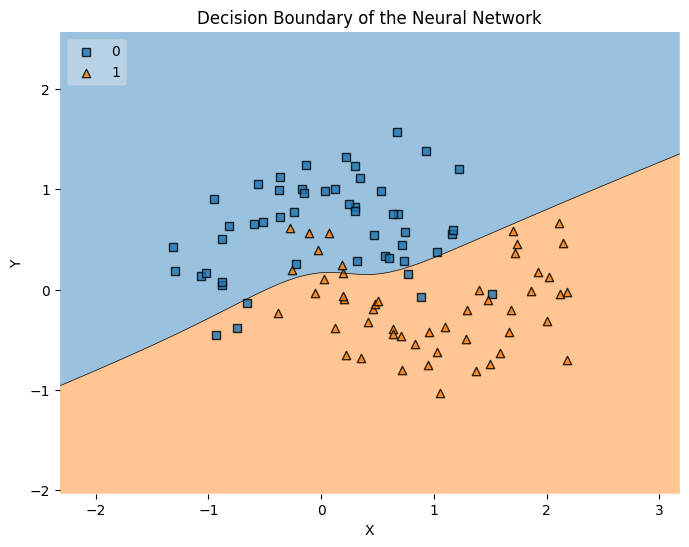

In [ ]:
from mlxtend.plotting import plot_decision_regions

plt.figure(figsize=(8, 6))
plot_decision_regions(X, y.astype(int), clf=model, legend=2)
plt.title("Decision Boundary of the Neural Network")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()